# 1. Setup & Configuration

In [1]:

# 1.1 Import Required Libraries

import os
import random
import platform
import numpy as np
import matplotlib.pyplot as plt
import cv2
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

print("Python:", platform.python_version())
print("NumPy:", np.__version__)
print("OpenCV:", cv2.__version__)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())


Python: 3.13.15
NumPy: 2.1.3
OpenCV: 4.14.0
PyTorch: 2.11.0+cu128
CUDA available: True


In [2]:

# 1.2 Project Configuration

CONFIG = {
    "data_dir": "/kaggle/input/datasets/tanlikesmath/the-oxfordiiit-pet-dataset/images",
    "image_size": 256,
    "batch_size": 8,
    "seed": 42,
    "learning_rate": 1e-3,
    "epochs": 30,
    "threshold": 0.5,
    "num_workers": 2
}

# Reproducibility
random.seed(CONFIG["seed"])
np.random.seed(CONFIG["seed"])
torch.manual_seed(CONFIG["seed"])

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(CONFIG["seed"])

# Device configuration
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Configuration:", CONFIG)
print("Device:", DEVICE)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "Not available")
print("Python, NumPy and PyTorch seeds:", CONFIG["seed"])


Configuration: {'data_dir': '/kaggle/input/datasets/tanlikesmath/the-oxfordiiit-pet-dataset/images', 'image_size': 256, 'batch_size': 8, 'seed': 42, 'learning_rate': 0.001, 'epochs': 30, 'threshold': 0.5, 'num_workers': 2}
Device: cuda
GPU: Tesla T4
Python, NumPy and PyTorch seeds: 42


In [3]:

# 1.3 Verify Dataset Structure

assert os.path.isdir(CONFIG["data_dir"]), (
    f"Dataset directory not found: {CONFIG['data_dir']}"
)

files = os.listdir(CONFIG["data_dir"])

print("Total files:", len(files))
print("Sample files:", files[:10])


Total files: 7394
Sample files: ['american_pit_bull_terrier_16.jpg', 'leonberger_200.jpg', 'english_cocker_spaniel_35.jpg', 'Siamese_67.jpg', 'boxer_77.jpg', 'saint_bernard_146.jpg', 'american_bulldog_37.jpg', 'Sphynx_239.jpg', 'Egyptian_Mau_164.jpg', 'Birman_116.jpg']


In [5]:

# 1.6 Download Segmentation Annotations

import urllib.request
import tarfile

ANNOTATION_URL = "https://www.robots.ox.ac.uk/~vgg/data/pets/data/annotations.tar.gz"
ANNOTATION_TAR = "/kaggle/working/annotations.tar.gz"
ANNOTATION_DIR = "/kaggle/working/annotations"

os.makedirs(ANNOTATION_DIR, exist_ok=True)

urllib.request.urlretrieve(ANNOTATION_URL, ANNOTATION_TAR)

with tarfile.open(ANNOTATION_TAR, "r:gz") as tar:
    tar.extractall(ANNOTATION_DIR)

print("Annotation download and extraction complete.")
print("Extracted contents:", os.listdir(ANNOTATION_DIR))


/tmp/ipykernel_49/1140594396.py:15: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall(ANNOTATION_DIR)


Annotation download and extraction complete.
Extracted contents: ['annotations']


In [6]:

# 1.7 Verify Image-Mask Pair

IMAGE_PATH = os.path.join(
    CONFIG["data_dir"], "american_pit_bull_terrier_16.jpg"
)
MASK_PATH = os.path.join(
    ANNOTATION_DIR, "annotations", "trimaps",
    "american_pit_bull_terrier_16.png"
)

print("Image exists:", os.path.isfile(IMAGE_PATH))
print("Mask exists:", os.path.isfile(MASK_PATH))


Image exists: True
Mask exists: True


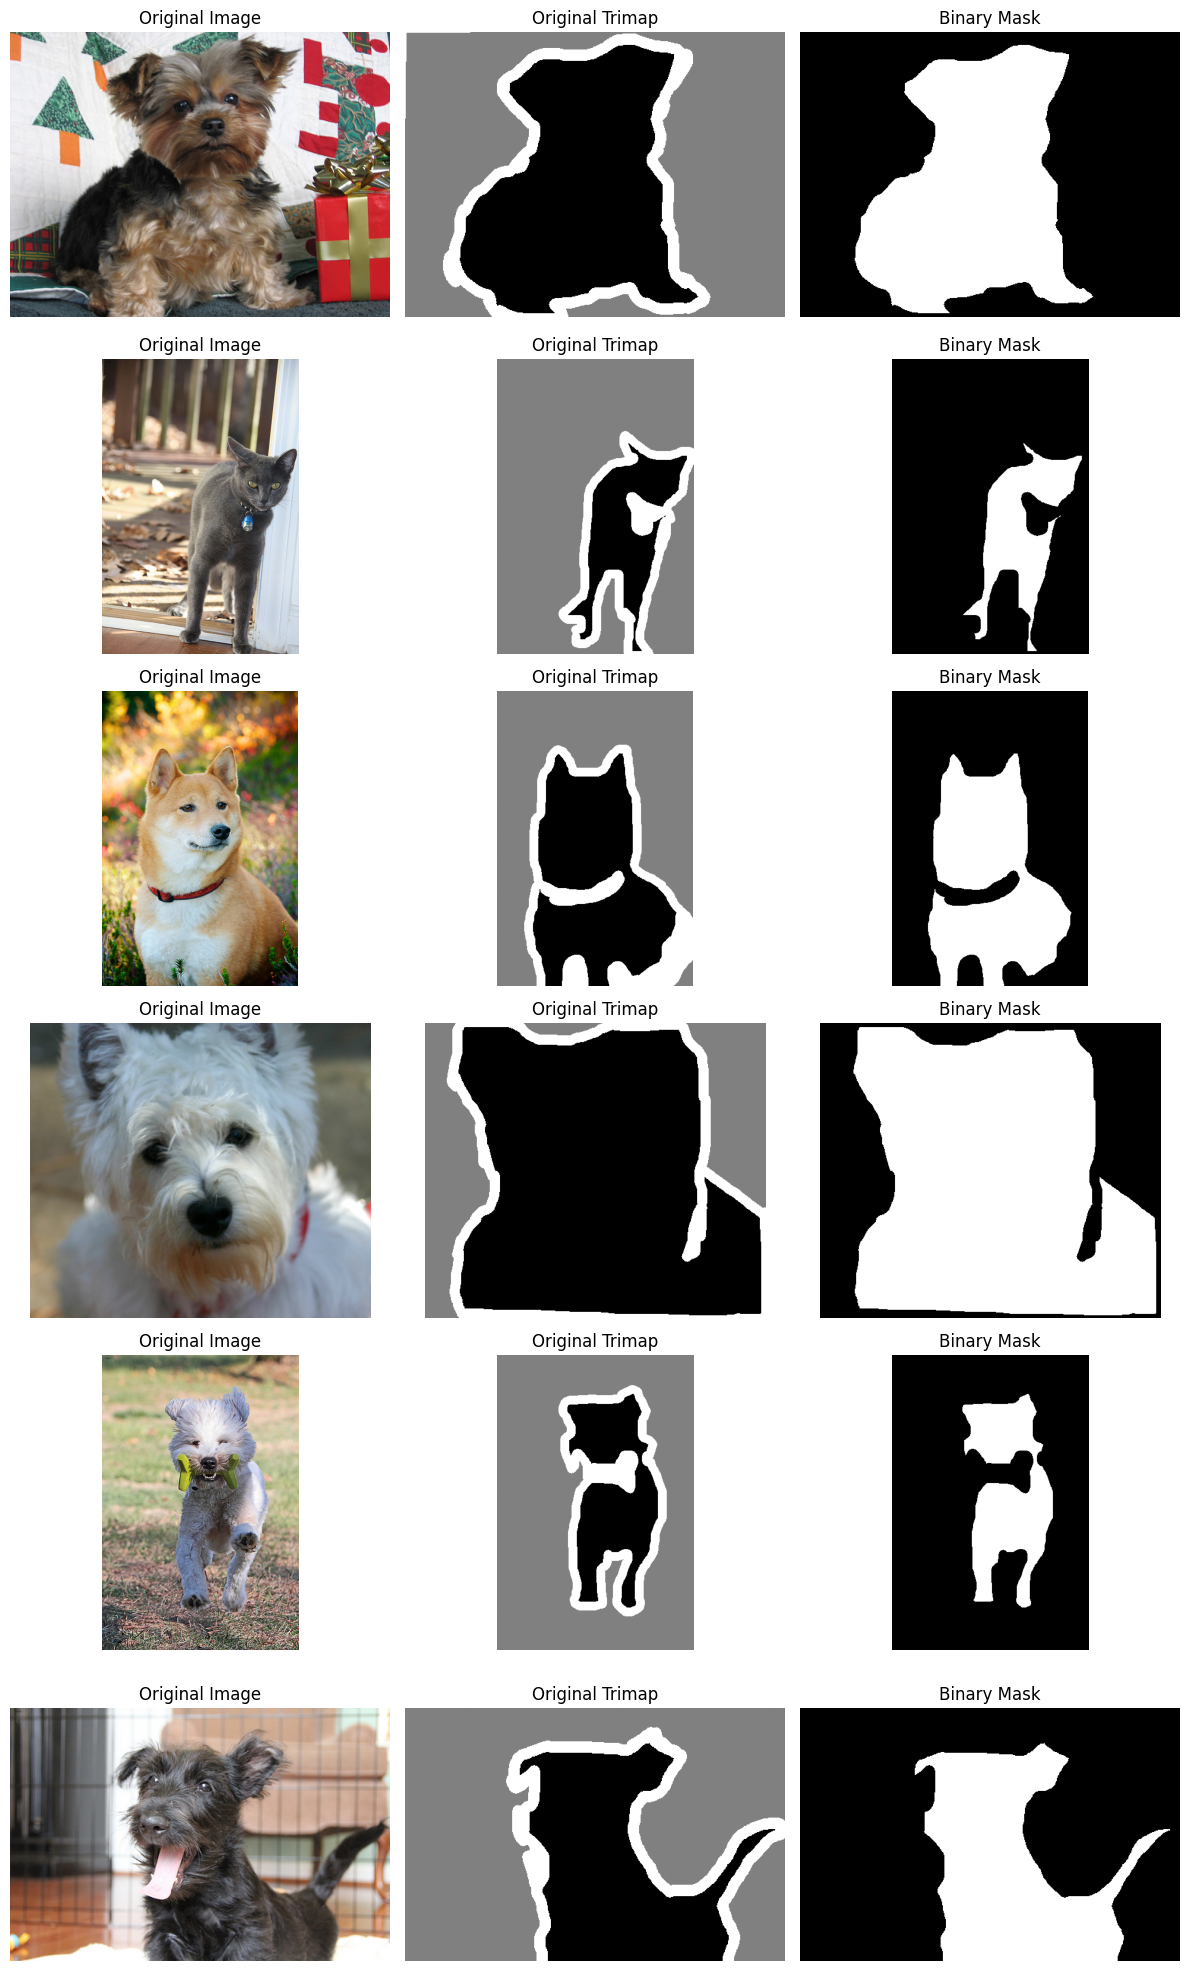

In [7]:

# 1.8 Visualize Image-Mask Pairs

import matplotlib.pyplot as plt
import random
import os
import numpy as np
from PIL import Image

IMAGE_DIR = CONFIG["data_dir"]
MASK_DIR = os.path.join(ANNOTATION_DIR, "annotations", "trimaps")

image_files = [
    f for f in os.listdir(IMAGE_DIR)
    if f.lower().endswith(".jpg")
]

random.seed(CONFIG["seed"])
samples = random.sample(image_files, 6)

fig, axes = plt.subplots(6, 3, figsize=(12, 20))

for i, filename in enumerate(samples):
    image_path = os.path.join(IMAGE_DIR, filename)
    mask_path = os.path.join(
        MASK_DIR, os.path.splitext(filename)[0] + ".png"
    )

    assert os.path.isfile(mask_path), f"Missing mask: {mask_path}"

    image = Image.open(image_path).convert("RGB")
    mask = np.array(Image.open(mask_path))

    # Convert trimap into binary mask:
    # 1 = pet foreground, 0 = background
    binary_mask = (mask == 1).astype(np.uint8)

    axes[i, 0].imshow(image)
    axes[i, 0].set_title("Original Image")

    axes[i, 1].imshow(mask, cmap="gray", vmin=1, vmax=3)
    axes[i, 1].set_title("Original Trimap")

    axes[i, 2].imshow(binary_mask, cmap="gray", vmin=0, vmax=1)
    axes[i, 2].set_title("Binary Mask")

    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.show()


- Original Image: The cat or dog is visible.
- 
- Original Trimap: The annotation contains foreground, background, and boundary labels.
- 
- Binary Mask: White represents the pet; black represents everything else, including the boundary in this initial conversion.
Important: This conversion uses mask == 1, meaning boundary pixels become background. We can use this simple convention for our baseline.

# 2. Dataset Audit and EDA

In [9]:

# 2.1 Count Images and Masks 
# What we are checking:
# - Each image has exactly one corresponding mask.
# - No annotation is missing.
# - No masks exist without matching images.

IMAGE_DIR = CONFIG["data_dir"]
MASK_DIR = os.path.join(ANNOTATION_DIR, "annotations", "trimaps")

image_files = sorted(
    f for f in os.listdir(IMAGE_DIR)
    if f.lower().endswith(".jpg") and not f.startswith("._")
)

mask_files = sorted(
    f for f in os.listdir(MASK_DIR)
    if f.lower().endswith(".png") and not f.startswith("._")
)

image_ids = {os.path.splitext(f)[0] for f in image_files}
mask_ids = {os.path.splitext(f)[0] for f in mask_files}

missing_masks = image_ids - mask_ids
orphan_masks = mask_ids - image_ids

print("Total images:", len(image_files))
print("Total masks:", len(mask_files))
print("Images without masks:", len(missing_masks))
print("Masks without images:", len(orphan_masks))

assert not missing_masks, f"Missing masks: {list(missing_masks)[:5]}"
assert not orphan_masks, f"Orphan masks: {list(orphan_masks)[:5]}"

print("Image-mask pairing verified successfully.")


Total images: 7390
Total masks: 7390
Images without masks: 0
Masks without images: 0
Image-mask pairing verified successfully.


In [10]:

# 2.2 Check Missing and Corrupt Files

bad_images = []
bad_masks = []
image_sizes = []
mask_values = set()

for filename in image_files:
    image_path = os.path.join(IMAGE_DIR, filename)
    mask_path = os.path.join(MASK_DIR, os.path.splitext(filename)[0] + ".png")

    image = cv2.imread(image_path)
    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)

    if image is None:
        bad_images.append(filename)
        continue

    if mask is None:
        bad_masks.append(os.path.basename(mask_path))
        continue

    image_sizes.append(image.shape[:2])
    mask_values.update(np.unique(mask).tolist())

print("Unreadable images:", len(bad_images))
print("Unreadable masks:", len(bad_masks))
print("Unique image dimensions:", len(set(image_sizes)))
print("Image dimensions (height, width):", sorted(set(image_sizes))[:10])
print("Original mask pixel values:", sorted(mask_values))

if bad_images:
    print("Examples of unreadable images:", bad_images[:5])

if bad_masks:
    print("Examples of unreadable masks:", bad_masks[:5])


Corrupt JPEG data: premature end of data segment
Corrupt JPEG data: 240 extraneous bytes before marker 0xd9


Unreadable images: 0
Unreadable masks: 0
Unique image dimensions: 1022
Image dimensions (height, width): [(103, 137), (108, 144), (112, 150), (116, 150), (125, 250), (134, 140), (135, 189), (143, 114), (145, 300), (149, 200)]
Original mask pixel values: [1, 2, 3]


The purpose of this cell is to check the quality and consistency of our dataset before training the U-Net model. We want to catch problems early so they don't cause errors later.

What each part does
Code	Purpose
bad_images = [] and bad_masks = []	Create lists to record files that cannot be opened.
image_sizes = []	Store the dimensions of each readable image.
mask_values = set()	Collect the unique pixel values found in the original masks.
cv2.imread(image_path)	Open each image and check whether it is readable.
cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)	Open its mask as a single-channel grayscale image.
if image is None	Detect an unreadable image.
if mask is None	Detect a missing or unreadable mask.
image_sizes.append(image.shape[:2])	Record image height and width.
mask_values.update(np.unique(mask).tolist())	Record all distinct pixel values in the masks.
print(...)	Summarize the results so we can inspect dataset quality.

Why these checks matter
1. File readability: We need images and masks that can be loaded successfully during training.

2. Image dimensions: Images may have different original sizes. This helps us understand what preprocessing will be needed before feeding them into U-Net.

3. Mask pixel values: The Oxford-IIIT Pet trimap uses three labels:
- 1 — Pet foreground
- 2 — Background
- 3 — Boundary between the pet and background
For our binary segmentation task, we have chosen to treat label 1 as foreground and labels 2 and 3 as background.

In [11]:

# 2.3 Inspect Image and Mask Properties

sample_name = image_files[0]

image_path = os.path.join(IMAGE_DIR, sample_name)
mask_path = os.path.join(MASK_DIR, os.path.splitext(sample_name)[0] + ".png")

image = cv2.cvtColor(cv2.imread(image_path), cv2.COLOR_BGR2RGB)
mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
binary_mask = (mask == 1).astype(np.uint8)

print("Sample:", sample_name)
print("\nImage")
print("Shape:", image.shape)
print("Data type:", image.dtype)
print("Pixel range:", image.min(), "to", image.max())

print("\nOriginal mask")
print("Shape:", mask.shape)
print("Data type:", mask.dtype)
print("Unique values:", np.unique(mask))

print("\nBinary mask")
print("Shape:", binary_mask.shape)
print("Data type:", binary_mask.dtype)
print("Unique values:", np.unique(binary_mask))
print("Foreground ratio:", round(binary_mask.mean() * 100, 2), "%")


Sample: Abyssinian_1.jpg

Image
Shape: (400, 600, 3)
Data type: uint8
Pixel range: 0 to 245

Original mask
Shape: (400, 600)
Data type: uint8
Unique values: [1 2 3]

Binary mask
Shape: (400, 600)
Data type: uint8
Unique values: [0 1]
Foreground ratio: 9.56 %


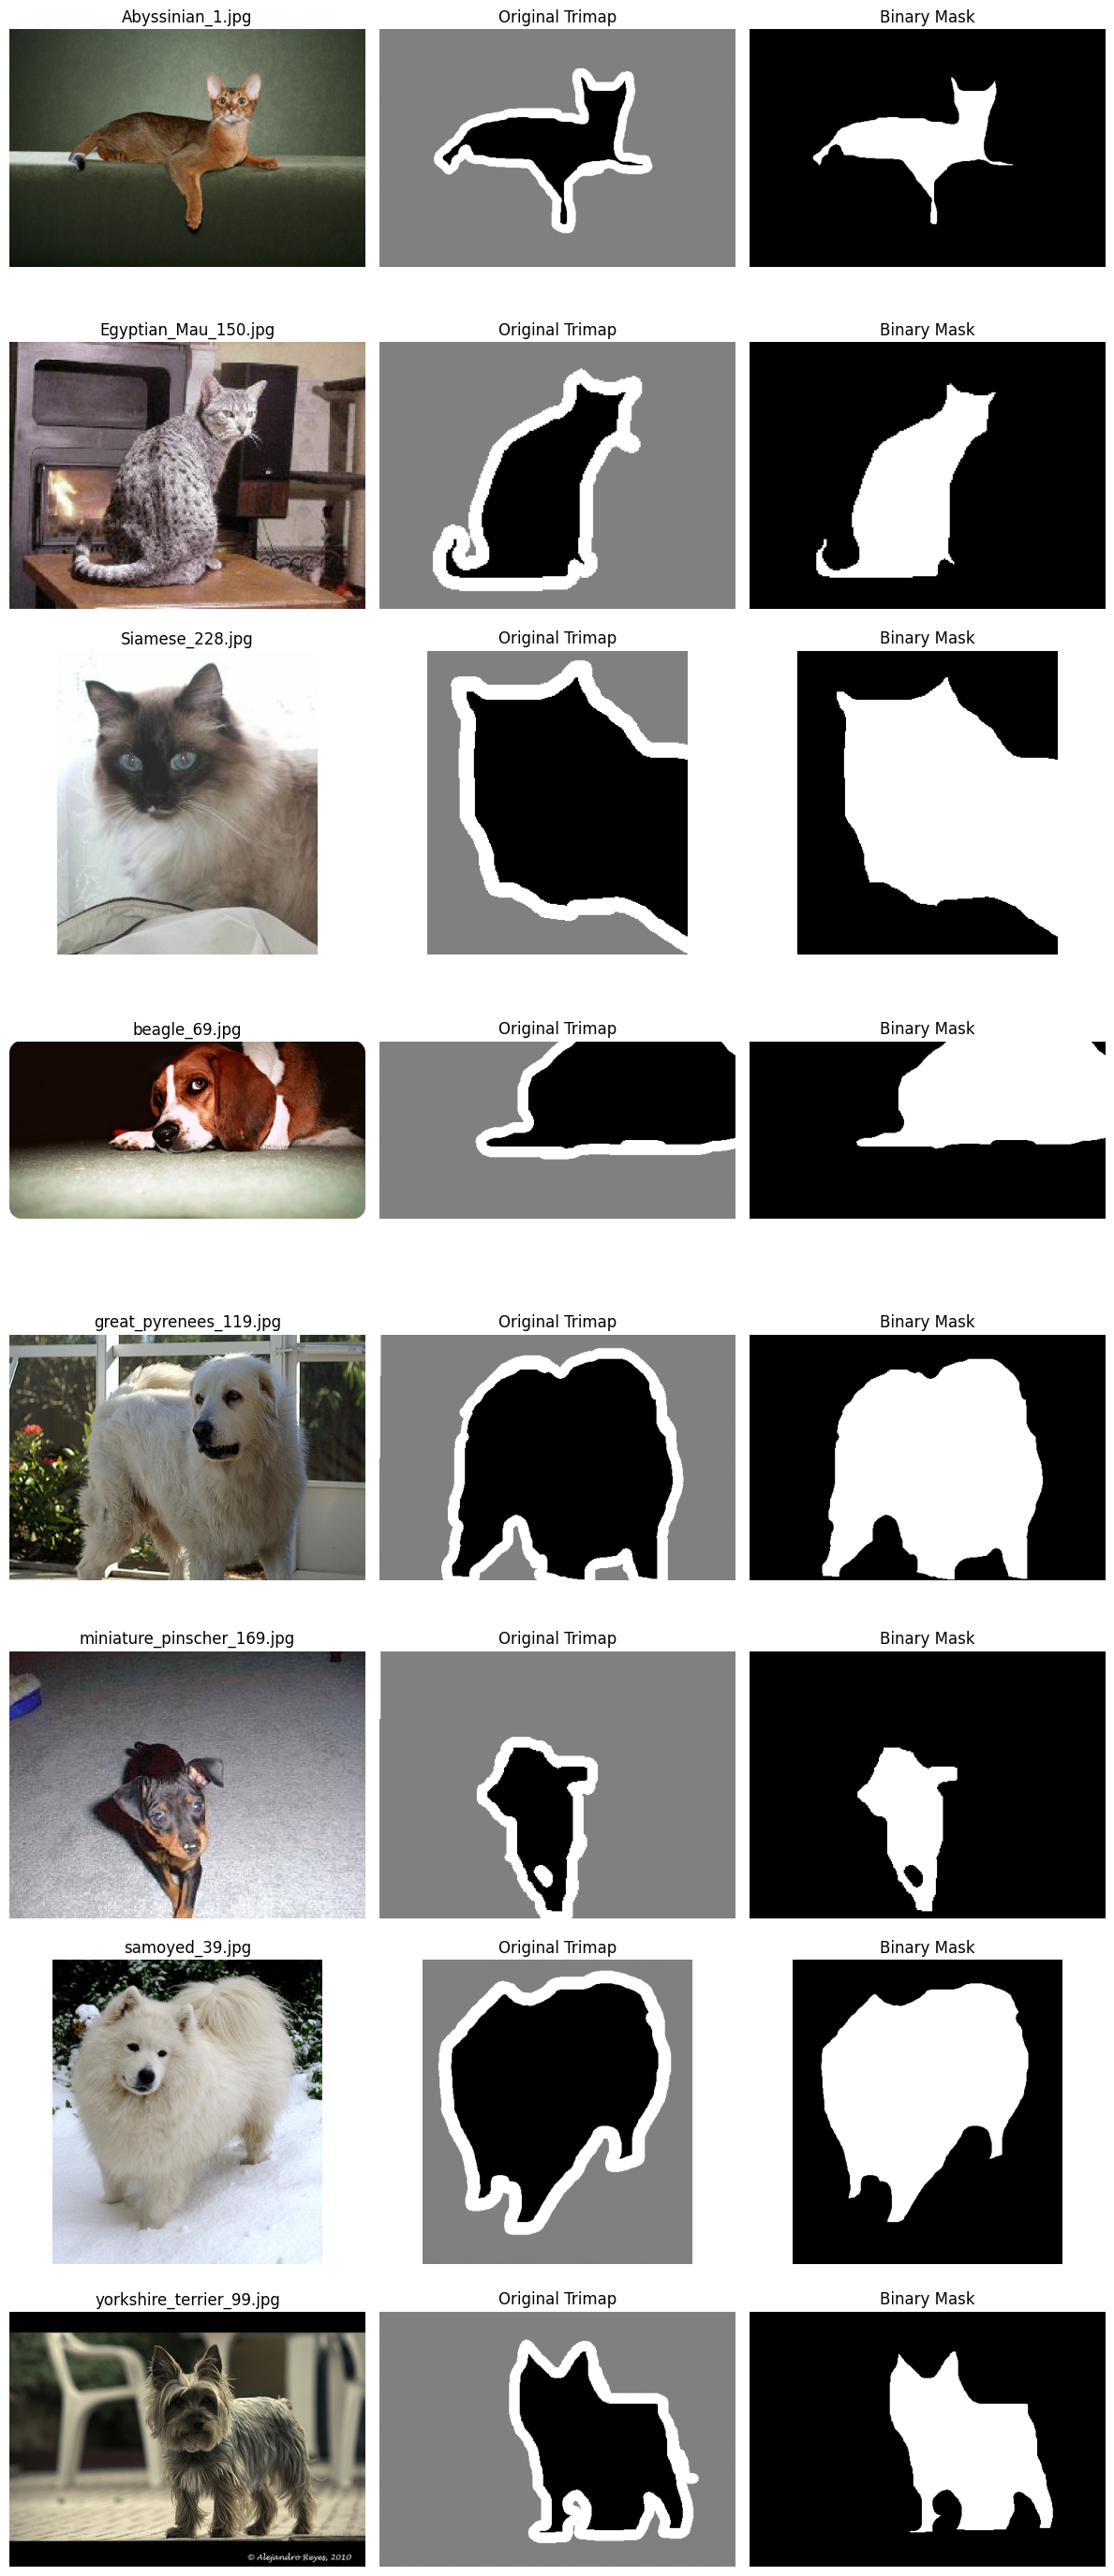

In [12]:

# 2.4 Visualize 8 Image-Mask Pairs

sample_indices = np.linspace(0, len(image_files) - 1, 8, dtype=int)

fig, axes = plt.subplots(8, 3, figsize=(12, 28))

for row, idx in enumerate(sample_indices):
    filename = image_files[idx]

    image_path = os.path.join(IMAGE_DIR, filename)
    mask_path = os.path.join(MASK_DIR, os.path.splitext(filename)[0] + ".png")

    image = cv2.cvtColor(cv2.imread(image_path), cv2.COLOR_BGR2RGB)
    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    binary_mask = (mask == 1).astype(np.uint8)

    axes[row, 0].imshow(image)
    axes[row, 0].set_title(filename)

    axes[row, 1].imshow(mask, cmap="gray", vmin=1, vmax=3)
    axes[row, 1].set_title("Original Trimap")

    axes[row, 2].imshow(binary_mask, cmap="gray", vmin=0, vmax=1)
    axes[row, 2].set_title("Binary Mask")

    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()
plt.show()


In [13]:

# 2.5 Class Balance and Dataset Split

from sklearn.model_selection import train_test_split

# Calculate foreground/background balance across all masks
foreground_pixels = 0
total_pixels = 0

for filename in mask_files:
    mask_path = os.path.join(MASK_DIR, filename)
    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    binary_mask = (mask == 1)

    foreground_pixels += binary_mask.sum()
    total_pixels += binary_mask.size

foreground_ratio = foreground_pixels / total_pixels
background_ratio = 1 - foreground_ratio

print(f"Foreground pixels: {foreground_ratio * 100:.2f}%")
print(f"Background pixels: {background_ratio * 100:.2f}%")

# Split image filenames: 70% train, 15% validation, 15% test
train_files, temp_files = train_test_split(
    image_files, test_size=0.30, random_state=CONFIG["seed"]
)

val_files, test_files = train_test_split(
    temp_files, test_size=0.50, random_state=CONFIG["seed"]
)

print("\nDataset split")
print("Training:", len(train_files))
print("Validation:", len(val_files))
print("Test:", len(test_files))
print("Total:", len(train_files) + len(val_files) + len(test_files))
print("Random seed:", CONFIG["seed"])


Foreground pixels: 29.52%
Background pixels: 70.48%

Dataset split
Training: 5173
Validation: 1108
Test: 1109
Total: 7390
Random seed: 42


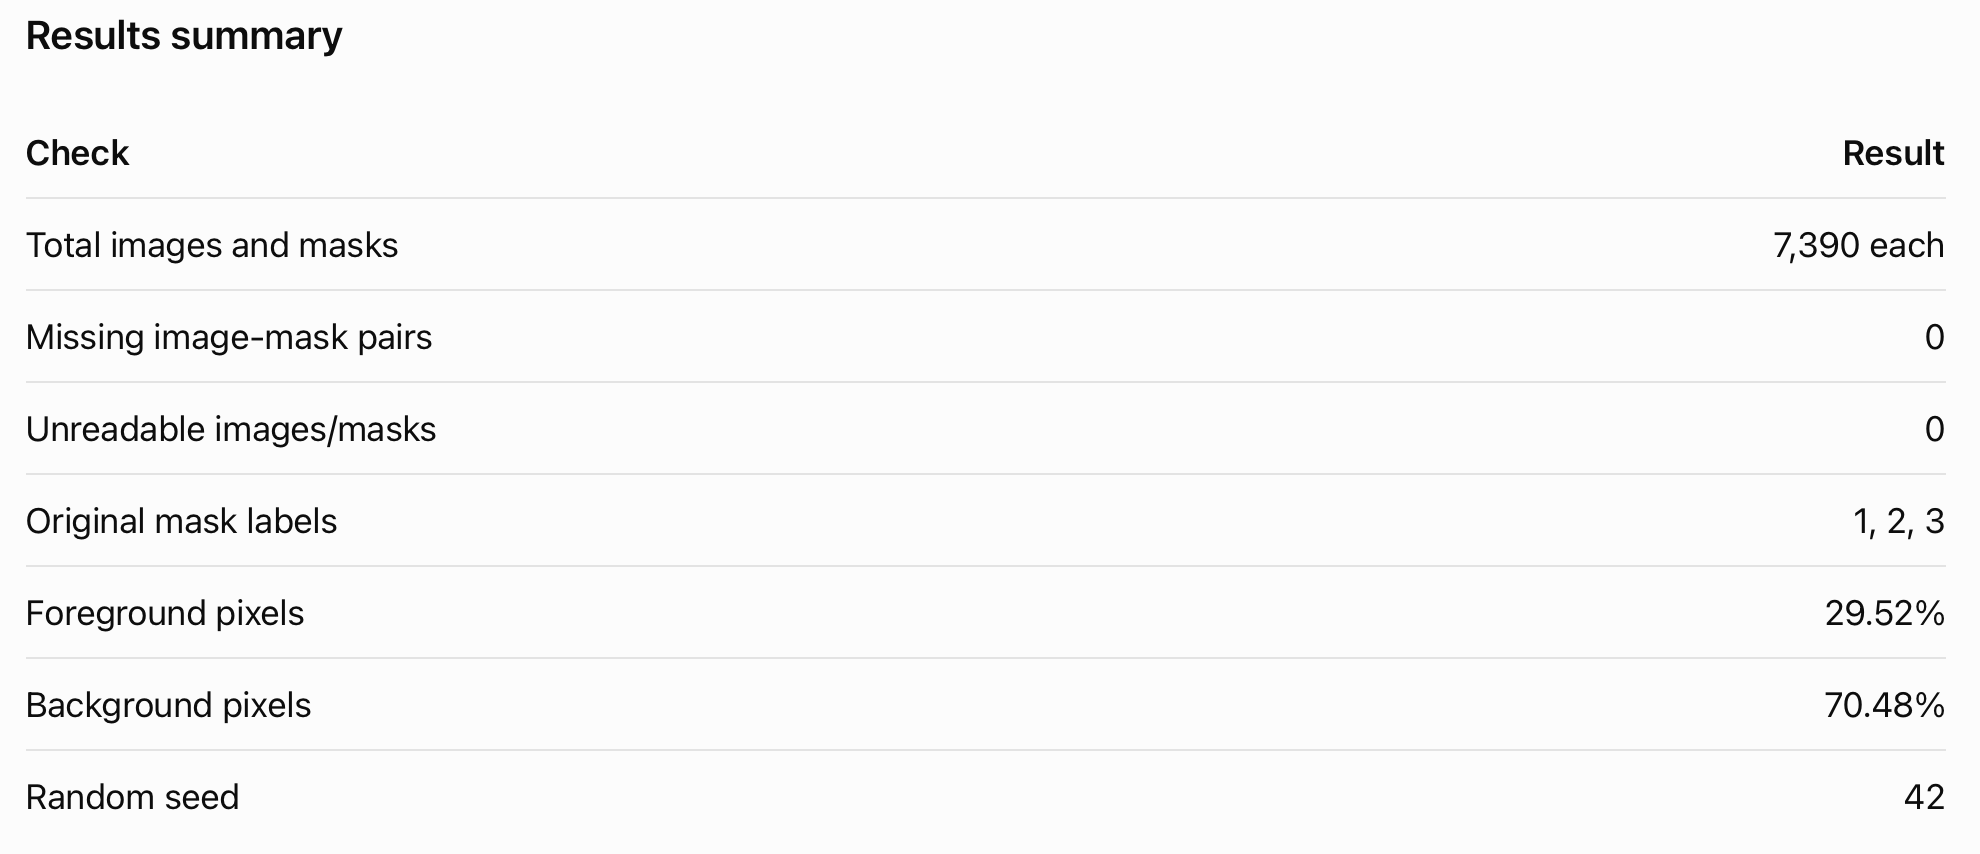
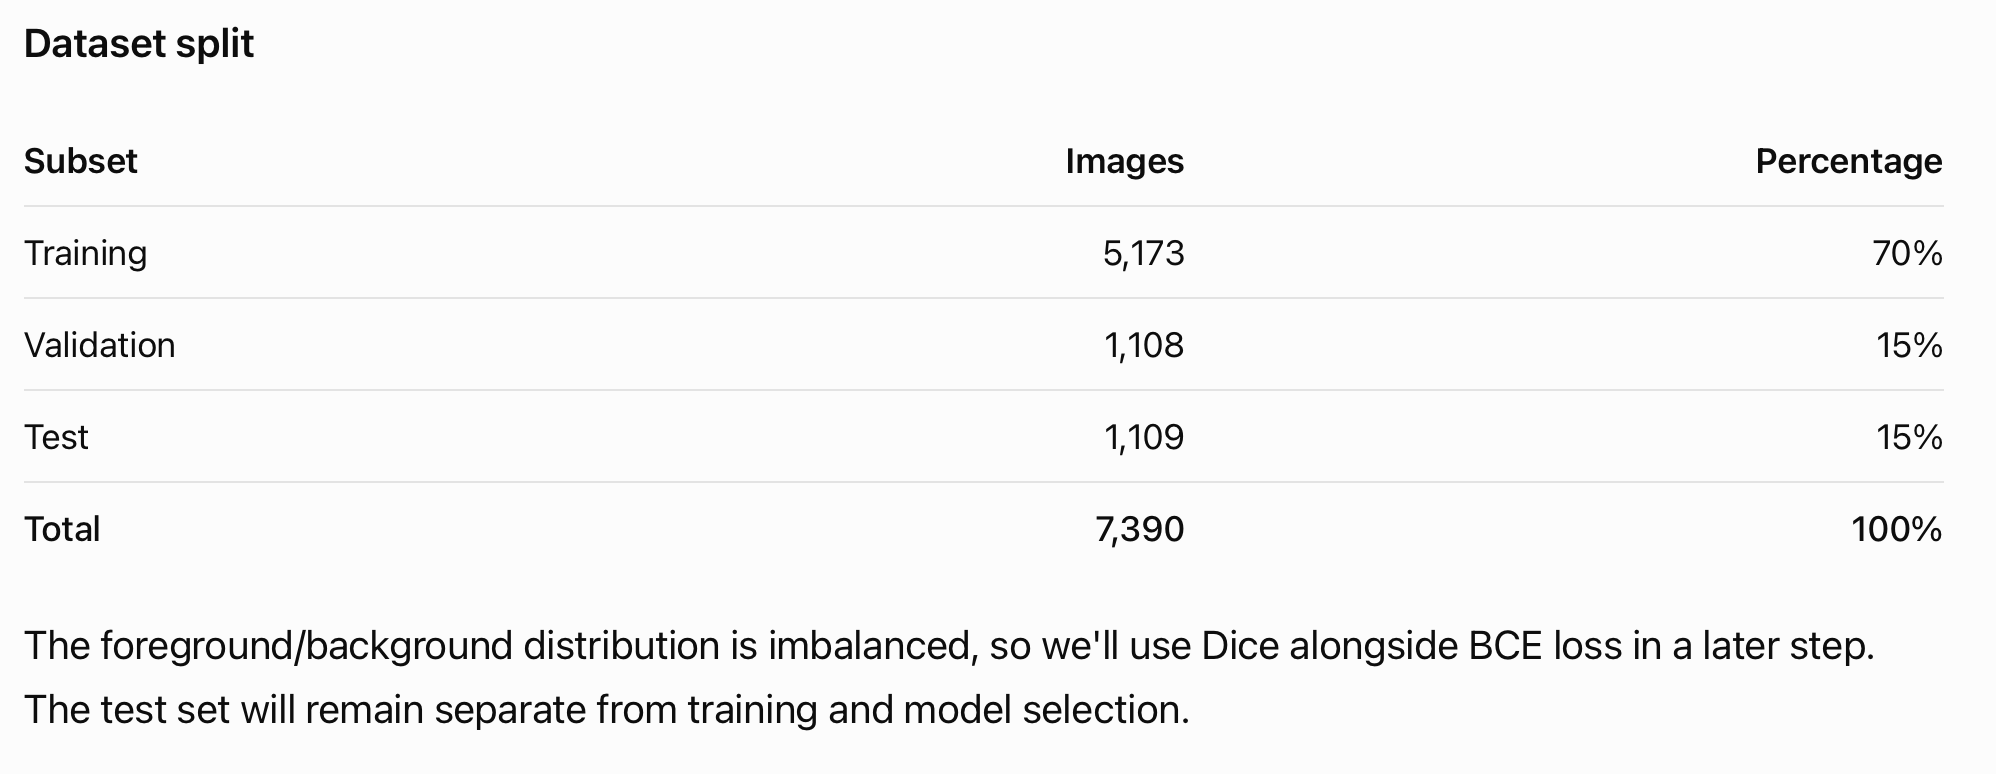

# 3. Preprocessing and Data Pipeline

3.1 Create the PyTorch Dataset

We'll create a dataset class that:

- Resizes images to 256 × 256 using bilinear interpolation.
- Resizes masks using nearest-neighbor interpolation to preserve binary labels.
- Normalizes image pixel values to [0, 1].
- Returns images in (3, 256, 256) format and masks in (1, 256, 256) format.

In [14]:

# 3.1 Create the PyTorch Dataset

class PetSegmentationDataset(Dataset):
    def __init__(self, filenames, image_dir, mask_dir, image_size=256):
        self.filenames = filenames
        self.image_dir = image_dir
        self.mask_dir = mask_dir
        self.image_size = image_size

    def __len__(self):
        return len(self.filenames)

    def __getitem__(self, idx):
        filename = self.filenames[idx]

        image_path = os.path.join(self.image_dir, filename)
        mask_path = os.path.join(
            self.mask_dir, os.path.splitext(filename)[0] + ".png"
        )

        image = cv2.cvtColor(
            cv2.imread(image_path), cv2.COLOR_BGR2RGB
        )
        mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)

        image = cv2.resize(
            image, (self.image_size, self.image_size),
            interpolation=cv2.INTER_LINEAR
        )
        mask = cv2.resize(
            mask, (self.image_size, self.image_size),
            interpolation=cv2.INTER_NEAREST
        )

        mask = (mask == 1).astype(np.float32)
        image = image.astype(np.float32) / 255.0

        image = torch.from_numpy(image).permute(2, 0, 1)
        mask = torch.from_numpy(mask).unsqueeze(0)

        return image, mask


train_dataset = PetSegmentationDataset(
    train_files, IMAGE_DIR, MASK_DIR, CONFIG["image_size"]
)
val_dataset = PetSegmentationDataset(
    val_files, IMAGE_DIR, MASK_DIR, CONFIG["image_size"]
)
test_dataset = PetSegmentationDataset(
    test_files, IMAGE_DIR, MASK_DIR, CONFIG["image_size"]
)

print("Train samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Test samples:", len(test_dataset))


Train samples: 5173
Validation samples: 1108
Test samples: 1109


Image shape: torch.Size([3, 256, 256])
Image dtype: torch.float32
Image range: 0.0 to 1.0

Mask shape: torch.Size([1, 256, 256])
Mask dtype: torch.float32
Mask unique values: [0.0, 1.0]


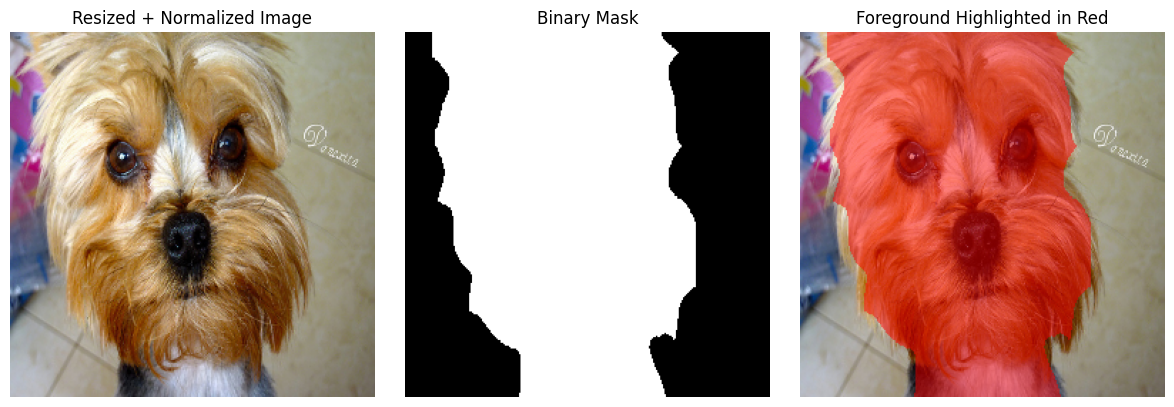

In [19]:

# 3.2 Visualize Preprocessed Image and Mask

image, mask = train_dataset[0]

image_np = image.permute(1, 2, 0).numpy()
mask_np = mask.squeeze(0).numpy()

# Highlight foreground pixels in red
overlay = image_np.copy()
foreground = mask_np == 1
overlay[foreground] = (
    0.5 * image_np[foreground] + 0.5 * np.array([1.0, 0.0, 0.0])
)

print("Image shape:", image.shape)
print("Image dtype:", image.dtype)
print("Image range:", image.min().item(), "to", image.max().item())

print("\nMask shape:", mask.shape)
print("Mask dtype:", mask.dtype)
print("Mask unique values:", torch.unique(mask).tolist())

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

axes[0].imshow(image_np)
axes[0].set_title("Resized + Normalized Image")

axes[1].imshow(mask_np, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Binary Mask")

axes[2].imshow(overlay)
axes[2].set_title("Foreground Highlighted in Red")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


In [20]:

# 3.3 Add Training-Only Augmentation

class PetSegmentationDataset(Dataset):
    def __init__(self, filenames, image_dir, mask_dir,
                 image_size=256, augment=False):
        self.filenames = filenames
        self.image_dir = image_dir
        self.mask_dir = mask_dir
        self.image_size = image_size
        self.augment = augment

    def __len__(self):
        return len(self.filenames)

    def __getitem__(self, idx):
        filename = self.filenames[idx]

        image_path = os.path.join(self.image_dir, filename)
        mask_path = os.path.join(
            self.mask_dir, os.path.splitext(filename)[0] + ".png"
        )

        image = cv2.cvtColor(
            cv2.imread(image_path), cv2.COLOR_BGR2RGB
        )
        mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)

        image = cv2.resize(
            image, (self.image_size, self.image_size),
            interpolation=cv2.INTER_LINEAR
        )
        mask = cv2.resize(
            mask, (self.image_size, self.image_size),
            interpolation=cv2.INTER_NEAREST
        )

        mask = (mask == 1).astype(np.float32)

        # Flip image and mask together during training only
        if self.augment and random.random() < 0.5:
            image = cv2.flip(image, 1)
            mask = cv2.flip(mask, 1)

        image = image.astype(np.float32) / 255.0

        image = torch.from_numpy(image.copy()).permute(2, 0, 1)
        mask = torch.from_numpy(mask.copy()).unsqueeze(0)

        return image, mask


train_dataset = PetSegmentationDataset(
    train_files, IMAGE_DIR, MASK_DIR,
    CONFIG["image_size"], augment=True
)

val_dataset = PetSegmentationDataset(
    val_files, IMAGE_DIR, MASK_DIR,
    CONFIG["image_size"], augment=False
)

test_dataset = PetSegmentationDataset(
    test_files, IMAGE_DIR, MASK_DIR,
    CONFIG["image_size"], augment=False
)

print("Training augmentation: horizontal flip")
print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Test samples:", len(test_dataset))


Training augmentation: horizontal flip
Training samples: 5173
Validation samples: 1108
Test samples: 1109


In [22]:

# 3.3 Training-Only Data Augmentation

class PetSegmentationDataset(Dataset):
    def __init__(self, filenames, image_dir, mask_dir,
                 image_size=256, augment=False):
        self.filenames = filenames
        self.image_dir = image_dir
        self.mask_dir = mask_dir
        self.image_size = image_size
        self.augment = augment

    def __len__(self):
        return len(self.filenames)

    def __getitem__(self, idx):
        filename = self.filenames[idx]

        image_path = os.path.join(self.image_dir, filename)
        mask_path = os.path.join(
            self.mask_dir, os.path.splitext(filename)[0] + ".png"
        )

        image = cv2.cvtColor(
            cv2.imread(image_path), cv2.COLOR_BGR2RGB
        )
        mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)

        size = self.image_size

        # Resize image and mask
        image = cv2.resize(image, (size, size),
                           interpolation=cv2.INTER_LINEAR)
        mask = cv2.resize(mask, (size, size),
                          interpolation=cv2.INTER_NEAREST)

        # Convert trimap to binary mask
        mask = (mask == 1).astype(np.uint8)

        if self.augment:
            # 1. Horizontal flip
            if random.random() < 0.5:
                image = cv2.flip(image, 1)
                mask = cv2.flip(mask, 1)

            # 2. Small rotation and affine transformation
            if random.random() < 0.5:
                angle = random.uniform(-15, 15)
                scale = random.uniform(0.9, 1.1)
                tx = random.uniform(-0.05, 0.05) * size
                ty = random.uniform(-0.05, 0.05) * size

                matrix = cv2.getRotationMatrix2D(
                    (size / 2, size / 2), angle, scale
                )
                matrix[0, 2] += tx
                matrix[1, 2] += ty

                image = cv2.warpAffine(
                    image, matrix, (size, size),
                    flags=cv2.INTER_LINEAR,
                    borderMode=cv2.BORDER_REFLECT_101
                )
                mask = cv2.warpAffine(
                    mask, matrix, (size, size),
                    flags=cv2.INTER_NEAREST,
                    borderMode=cv2.BORDER_CONSTANT,
                    borderValue=0
                )

            # 3. Random crop and resize (crop at least 80% per dimension)
            if random.random() < 0.5:
                crop_size = random.uniform(0.8, 1.0)
                crop_h = int(size * crop_size)
                crop_w = int(size * crop_size)

                top = random.randint(0, size - crop_h)
                left = random.randint(0, size - crop_w)

                image_crop = image[top:top + crop_h, left:left + crop_w]
                mask_crop = mask[top:top + crop_h, left:left + crop_w]

                image = cv2.resize(
                    image_crop, (size, size),
                    interpolation=cv2.INTER_LINEAR
                )
                mask = cv2.resize(
                    mask_crop, (size, size),
                    interpolation=cv2.INTER_NEAREST
                )

            # 4. Brightness and contrast (image only)
            if random.random() < 0.5:
                alpha = random.uniform(0.8, 1.2)  # Contrast
                beta = random.uniform(-20, 20)    # Brightness
                image = np.clip(
                    alpha * image.astype(np.float32) + beta,
                    0, 255
                ).astype(np.uint8)

        # Normalize image and prepare tensors
        image = image.astype(np.float32) / 255.0
        mask = mask.astype(np.float32)

        image = torch.from_numpy(image.copy()).permute(2, 0, 1)
        mask = torch.from_numpy(mask.copy()).unsqueeze(0)

        return image, mask


# Augmentation enabled only for training
train_dataset = PetSegmentationDataset(
    train_files, IMAGE_DIR, MASK_DIR,
    CONFIG["image_size"], augment=True
)

val_dataset = PetSegmentationDataset(
    val_files, IMAGE_DIR, MASK_DIR,
    CONFIG["image_size"], augment=False
)

test_dataset = PetSegmentationDataset(
    test_files, IMAGE_DIR, MASK_DIR,
    CONFIG["image_size"], augment=False
)

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Test samples:", len(test_dataset))
print("Training augmentations: flip, affine, crop/scale, brightness/contrast")


Training samples: 5173
Validation samples: 1108
Test samples: 1109
Training augmentations: flip, affine, crop/scale, brightness/contrast


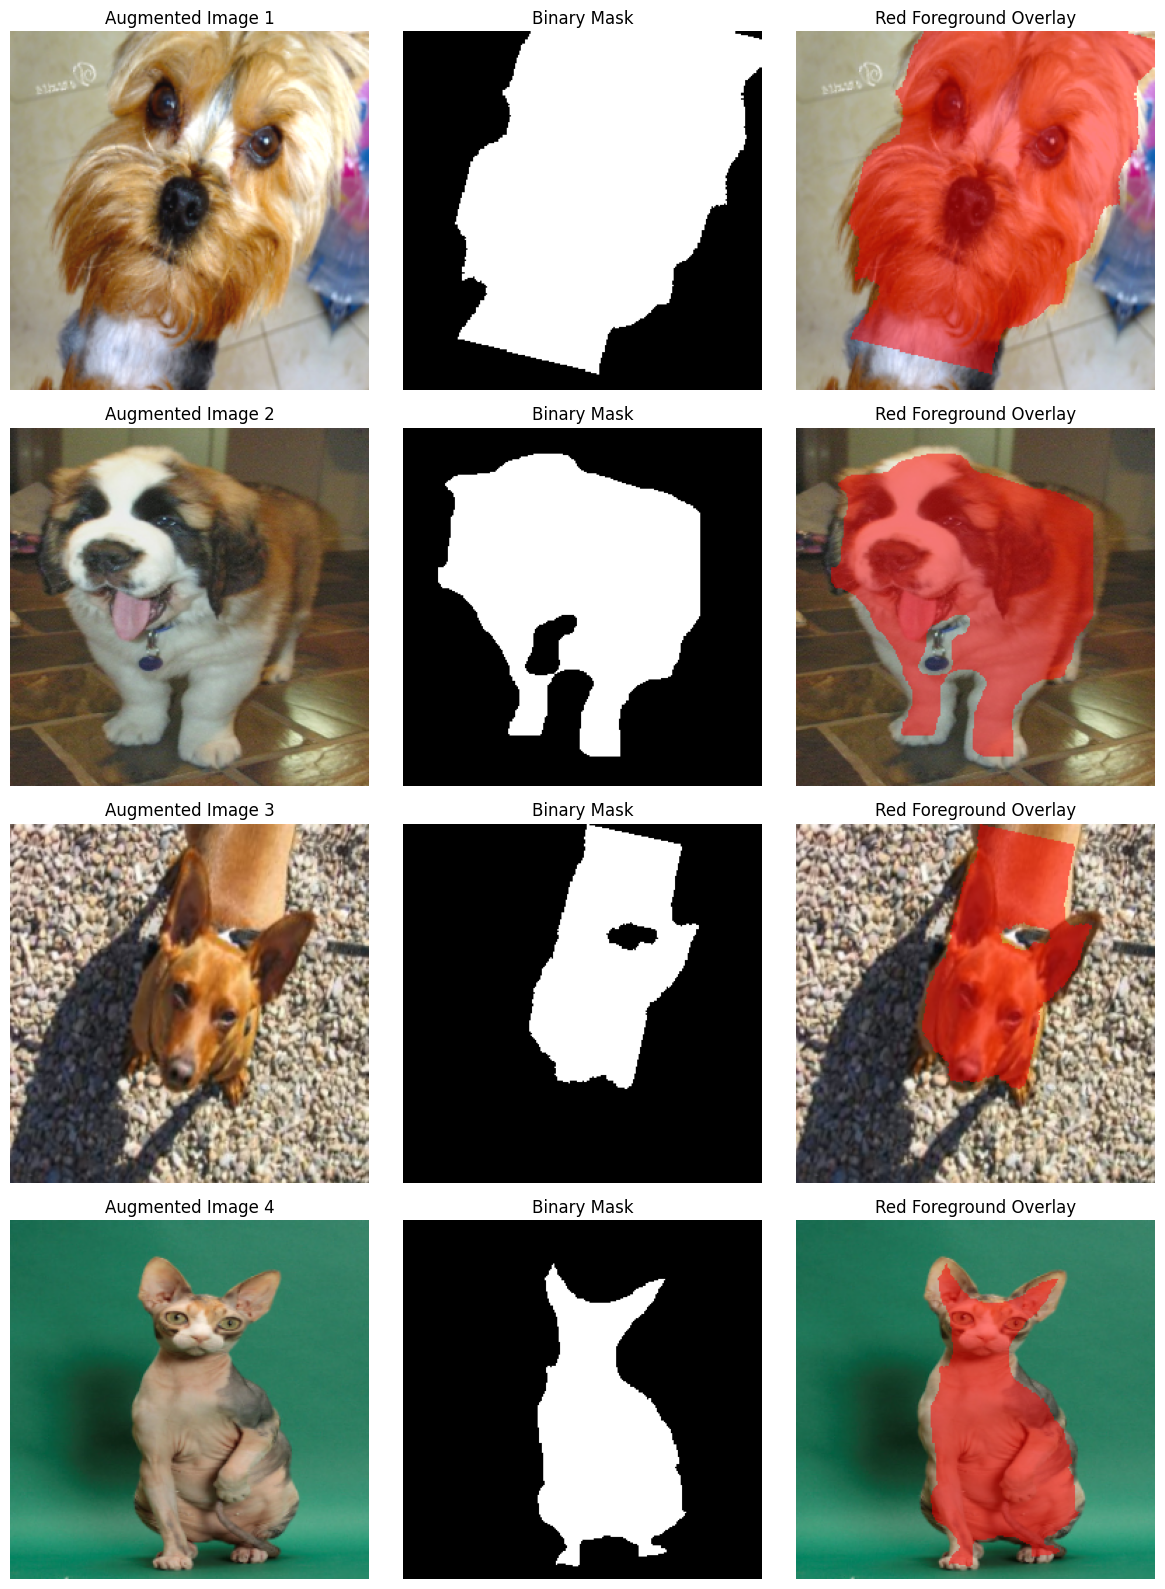

Image tensor shape: torch.Size([3, 256, 256])
Mask tensor shape: torch.Size([1, 256, 256])
Mask values: [0.0, 1.0]


In [23]:

# 3.4 Visualize Augmented Mini-Batch

fig, axes = plt.subplots(4, 3, figsize=(12, 16))

for i in range(4):
    image, mask = train_dataset[i]

    image_np = image.permute(1, 2, 0).numpy()
    mask_np = mask.squeeze(0).numpy()

    overlay = image_np.copy()
    foreground = mask_np == 1
    overlay[foreground] = (
        0.5 * image_np[foreground]
        + 0.5 * np.array([1.0, 0.0, 0.0])
    )

    axes[i, 0].imshow(image_np)
    axes[i, 0].set_title(f"Augmented Image {i + 1}")

    axes[i, 1].imshow(mask_np, cmap="gray", vmin=0, vmax=1)
    axes[i, 1].set_title("Binary Mask")

    axes[i, 2].imshow(overlay)
    axes[i, 2].set_title("Red Foreground Overlay")

    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.show()

print("Image tensor shape:", image.shape)
print("Mask tensor shape:", mask.shape)
print("Mask values:", torch.unique(mask).tolist())


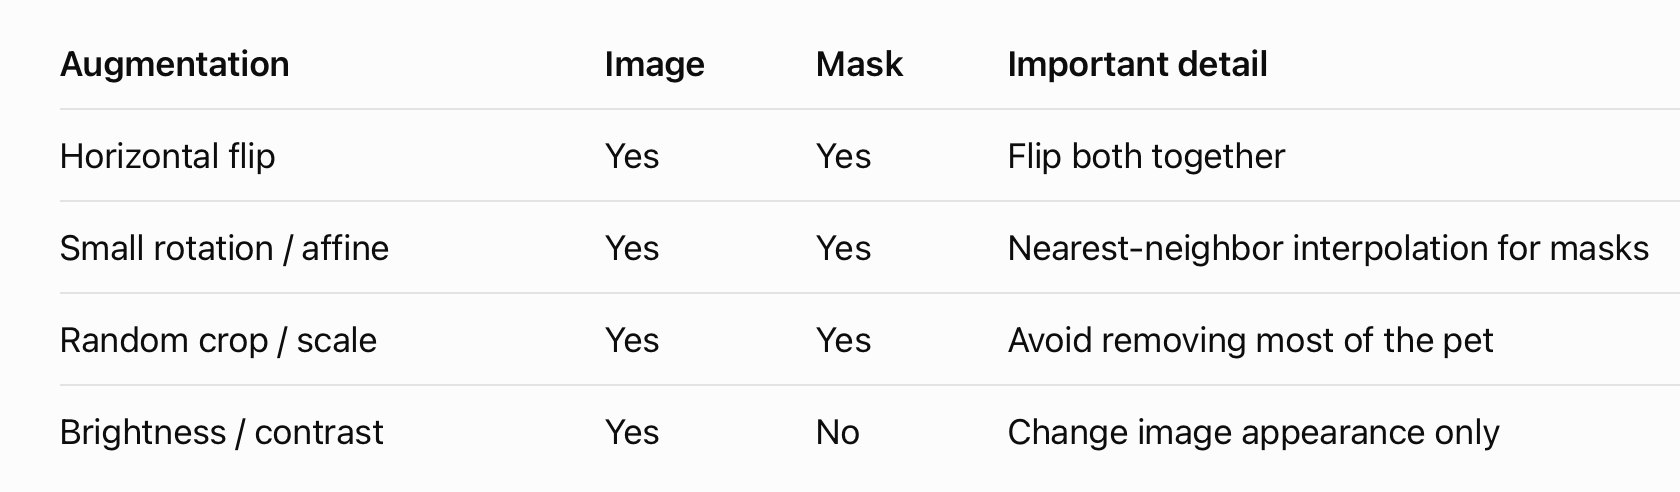

Image batch shape: torch.Size([8, 3, 256, 256])
Mask batch shape: torch.Size([8, 1, 256, 256])
Image value range: 0.0 to 1.0
Mask values: [0.0, 1.0]


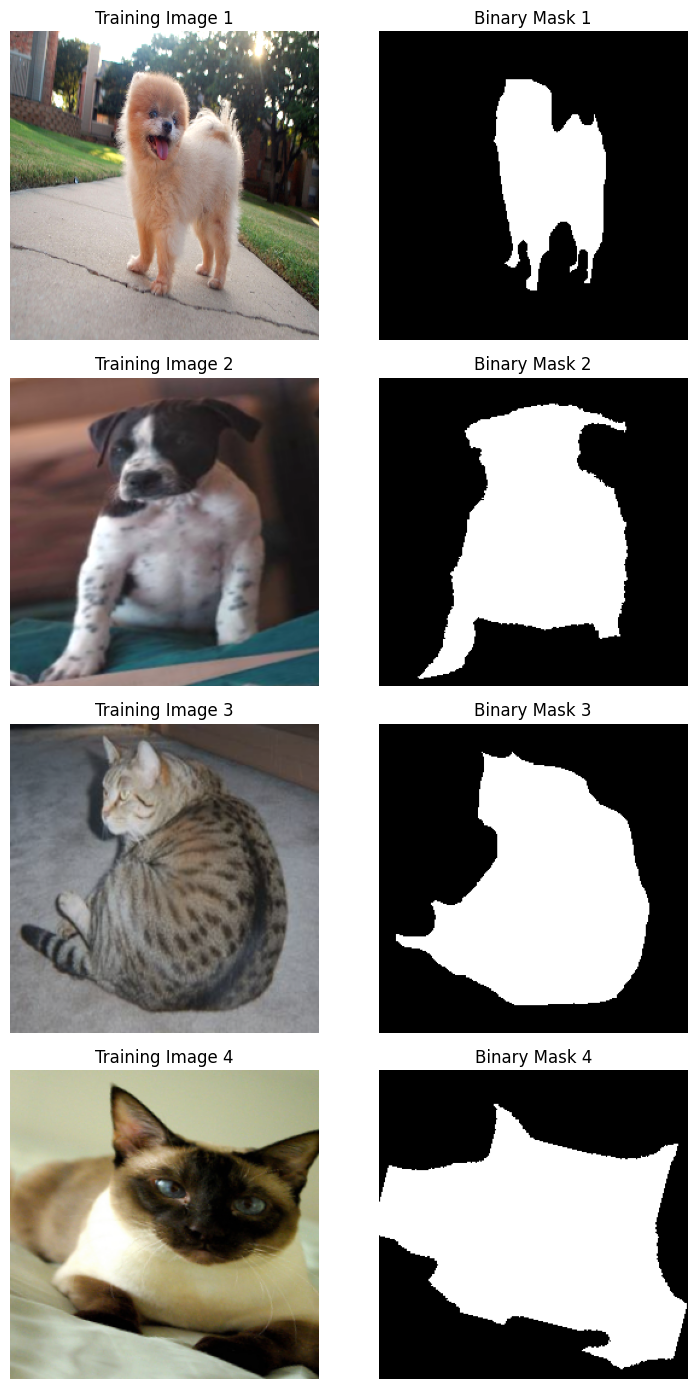

Train batches: 647
Validation batches: 139
Test batches: 139


In [24]:

# 3.5 Create DataLoaders and Verify a Mini-Batch

train_loader = DataLoader(
    train_dataset,
    batch_size=CONFIG["batch_size"],
    shuffle=True,
    num_workers=CONFIG["num_workers"],
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=CONFIG["batch_size"],
    shuffle=False,
    num_workers=CONFIG["num_workers"],
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=CONFIG["batch_size"],
    shuffle=False,
    num_workers=CONFIG["num_workers"],
    pin_memory=torch.cuda.is_available()
)

images, masks = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Mask batch shape:", masks.shape)
print("Image value range:", images.min().item(), "to", images.max().item())
print("Mask values:", torch.unique(masks).tolist())

fig, axes = plt.subplots(4, 2, figsize=(8, 14))

for i in range(4):
    axes[i, 0].imshow(images[i].permute(1, 2, 0).numpy())
    axes[i, 0].set_title(f"Training Image {i + 1}")

    axes[i, 1].imshow(masks[i, 0].numpy(), cmap="gray", vmin=0, vmax=1)
    axes[i, 1].set_title(f"Binary Mask {i + 1}")

    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.show()

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))


# 4. Baseline Model — U-Net Architecture

# 5. Loss Functions & Evaluation Metrics

# 6. Training Protocol

# 7. Qualitative Evaluation and Error Analysis